<sub>**The Annotated ML Handbook** · Part II: NumPy · by Mahir Absar Khan</sub>

# Chapter 10: Machine learning from scratch with NumPy

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-2-numpy/10-numpy-ml-scratch.ipynb) &nbsp; [📚 Contents](../../book/README.md) &nbsp; [🌐 Web edition](https://mahir-606.github.io/annotated-ml-handbook/)

*Run the setup cell first, then read and run the cells from top to bottom. Every code cell is followed by a table explaining what each line does.*

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

Libraries hide the maths. Building a few models by hand, once, makes everything in Parts V and VI less magical: you will know what `fit` is doing, why scaling matters, and where a learning rate comes in.

## 10.1 The core idea of supervised learning · *Beginner*

> **📖 Definitions**
>
> **Model**: a mathematical function with adjustable parameters that maps inputs (features) to outputs (predictions).
>
> **Parameter**: a number inside a model that is learned from data, such as a regression coefficient or a neural-network weight.
>
> **Loss function**: a measure of how wrong a model's predictions are, which training tries to minimise. Examples: mean squared error, cross-entropy.


You have inputs **X** (shape `(n_samples, n_features)`) and targets **y** (shape `(n_samples,)`). A model is a function with adjustable **parameters**. *Training* means searching for parameter values that make predictions close to `y`, measured by a **loss function**. Everything else is detail.

## 10.2 Making a dataset and splitting it · *Beginner*

**Synthetic data with a known answer**

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)
n = 200
X = rng.uniform(0, 10, size=(n, 1))
true_w, true_b = 2.5, -4.0
y = true_w * X[:, 0] + true_b + rng.normal(0, 2, n)

idx = rng.permutation(n)
split = int(0.8 * n)
train_idx, test_idx = idx[:split], idx[split:]
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
print(X_train.shape, X_test.shape, y_train.shape)

(160, 1) (40, 1) (160,)


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>import numpy as np</code></td><td>Import NumPy (the array library) under the short name <code>np</code>.</td></tr>
<tr><td><code>import matplotlib.pyplot as plt</code></td><td>Import Matplotlib&#x27;s plotting interface under the short name <code>plt</code>.</td></tr>
<tr><td><code>rng = np.random.default_rng(7)</code></td><td>Seeded random generator for reproducible data.</td></tr>
<tr><td><code>n = 200</code></td><td>Number of samples.</td></tr>
<tr><td><code>X = rng.uniform(0, 10, size=(n, 1))</code></td><td>One feature, 200 samples, shape (200, 1).</td></tr>
<tr><td><code>true_w, true_b = 2.5, -4.0</code></td><td>The &quot;truth&quot; we hope to recover.</td></tr>
<tr><td><code>y = true_w * X[:, 0] + true_b + rng.normal(0, 2, n)</code></td><td>Linear signal + Gaussian noise. X[:, 0] makes it 1-D.</td></tr>
<tr><td><code>idx = rng.permutation(n)</code></td><td>Shuffle the row indices.</td></tr>
<tr><td><code>split = int(0.8 * n)</code></td><td>80% train, 20% test.</td></tr>
<tr><td><code>train_idx, test_idx = idx[:split], idx[split:]</code></td><td>First 160 shuffled indices for training, the remaining 40 for testing.</td></tr>
<tr><td><code>X_train, X_test = X[train_idx], X[test_idx]</code></td><td>Fancy indexing selects the rows.</td></tr>
<tr><td><code>y_train, y_test = y[train_idx], y[test_idx]</code></td><td>Split the targets with the same indices.</td></tr>
<tr><td><code>print(X_train.shape, X_test.shape, y_train.shape)</code></td><td>(160, 1) (40, 1) (160,).</td></tr>
</table>
</details>

## 10.3 Linear regression, the closed-form way · *Intermediate*

For a linear model ŷ = Xw, the weights that minimise squared error solve the *normal equations*. We add a column of ones so the model can learn an intercept.

**Least squares in three lines**

In [3]:
def add_bias(X):
    return np.column_stack([np.ones(len(X)), X])

Xb = add_bias(X_train)
w, *_ = np.linalg.lstsq(Xb, y_train, rcond=None)
print(f"intercept={w[0]:.3f}  slope={w[1]:.3f}")

y_pred = add_bias(X_test) @ w
mse = np.mean((y_test - y_pred) ** 2)
r2 = 1 - np.sum((y_test - y_pred) ** 2) / np.sum((y_test - y_test.mean()) ** 2)
print(f"test MSE={mse:.3f}  RMSE={np.sqrt(mse):.3f}  R2={r2:.3f}")

intercept=-3.909  slope=2.472
test MSE=4.333  RMSE=2.082  R2=0.927


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>def add_bias(X):</code></td><td>Define a function <code>add_bias</code> that takes <code>X</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;return np.column_stack([np.ones(len(X)), X])</code></td><td>Prepend a column of 1s: its weight becomes the intercept b.</td></tr>
<tr><td><code>Xb = add_bias(X_train)</code></td><td>Shape (160, 2).</td></tr>
<tr><td><code>w, *_ = np.linalg.lstsq(Xb, y_train, rcond=None)</code></td><td>Solves min ||Xb w - y||^2 stably (better than inv(X.T X) X.T y).</td></tr>
<tr><td><code>print(f&quot;intercept={w[0]:.3f}  slope={w[1]:.3f}&quot;)</code></td><td>Close to the true -4.0 and 2.5.</td></tr>
<tr><td><code>y_pred = add_bias(X_test) @ w</code></td><td>Predictions on unseen data.</td></tr>
<tr><td><code>mse = np.mean((y_test - y_pred) ** 2)</code></td><td>Mean squared error.</td></tr>
<tr><td><code>r2 = 1 - np.sum((y_test - y_pred) ** 2) / np.sum((y_test - y_test.mean()) ** 2)</code></td><td>R²: share of variance explained.</td></tr>
<tr><td><code>print(f&quot;test MSE={mse:.3f}  RMSE={np.sqrt(mse):.3f}  R2={r2:.3f}&quot;)</code></td><td>RMSE is the square root of MSE, in the units of y.</td></tr>
</table>
</details>

## 10.4 Linear regression by gradient descent · *Intermediate*

> **📖 Definitions**
>
> **Gradient**: the vector of partial derivatives of the loss with respect to each parameter. It points in the direction of steepest increase.
>
> **Gradient descent**: an algorithm that repeatedly moves the parameters a small step against the gradient, so the loss decreases.
>
> **Learning rate**: the size of each gradient-descent step. Too small is slow; too large overshoots and can diverge.
>
> **Epoch**: one full pass through the training data.


Most ML models (and all neural networks) have no closed-form solution. Instead we start with a guess and repeatedly step **downhill** on the loss. For MSE loss L = mean((Xw − y)²), the gradient is ∇L = (2/n)·Xᵀ(Xw − y).

**Gradient descent, step by step**

In [4]:
def gradient_descent(X, y, lr=0.01, epochs=500):
    Xb = add_bias(X)
    w = np.zeros(Xb.shape[1])
    history = []
    for epoch in range(epochs):
        error = Xb @ w - y
        loss = np.mean(error ** 2)
        grad = 2 / len(y) * Xb.T @ error
        w -= lr * grad
        history.append(loss)
    return w, history

w_gd, hist = gradient_descent(X_train, y_train, lr=0.02, epochs=2000)
print(f"GD intercept={w_gd[0]:.3f} slope={w_gd[1]:.3f} final loss={hist[-1]:.3f}")

GD intercept=-3.909 slope=2.472 final loss=3.620


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>def gradient_descent(X, y, lr=0.01, epochs=500):</code></td><td>Define a function <code>gradient_descent</code> that takes <code>X</code>, <code>y</code>, <code>lr</code> and <code>epochs</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;Xb = add_bias(X)</code></td><td>Add the column of ones.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;w = np.zeros(Xb.shape[1])</code></td><td>Start from all-zero weights.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;history = []</code></td><td>Will record the loss at each epoch.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;for epoch in range(epochs):</code></td><td>Loop over <code>range(epochs)</code>, naming each item <code>epoch</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;error = Xb @ w - y</code></td><td>Residuals for every sample at once (vectorized).</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;loss = np.mean(error ** 2)</code></td><td>Current mean squared error.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;grad = 2 / len(y) * Xb.T @ error</code></td><td>The gradient: direction of steepest INCREASE in loss.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;w -= lr * grad</code></td><td>Step the opposite way, scaled by the learning rate.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;history.append(loss)</code></td><td>Store it for the learning-curve plot.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;return w, history</code></td><td>Send <code>w, history</code> back to the caller.</td></tr>
<tr><td><code>w_gd, hist = gradient_descent(X_train, y_train, lr=0.02, epochs=2000)</code></td><td>Train for 2000 epochs with learning rate 0.02.</td></tr>
<tr><td><code>print(f&quot;GD intercept={w_gd[0]:.3f} slope={w_gd[1]:.3f} final loss={hist[-1]:.3f}&quot;)</code></td><td>Should match the closed-form solution closely.</td></tr>
</table>
</details>

**Visualise the fit and the learning curve**

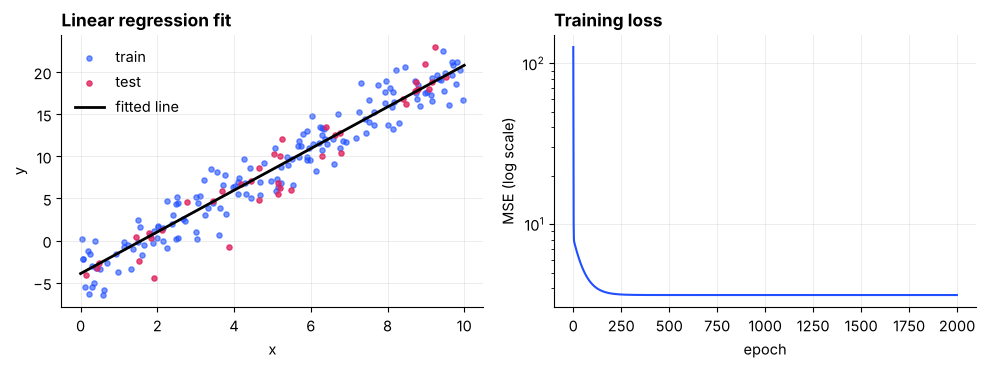

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
ax1.scatter(X_train, y_train, s=14, alpha=0.6, label="train")
ax1.scatter(X_test, y_test, s=14, alpha=0.8, label="test")
xs = np.linspace(0, 10, 100).reshape(-1, 1)
ax1.plot(xs, add_bias(xs) @ w_gd, color="black", lw=2, label="fitted line")
ax1.set(xlabel="x", ylabel="y", title="Linear regression fit")
ax1.legend()
ax2.plot(hist)
ax2.set(xlabel="epoch", ylabel="MSE (log scale)", yscale="log", title="Training loss")
plt.tight_layout()
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))</code></td><td>One figure, two side-by-side panels (axes).</td></tr>
<tr><td><code>ax1.scatter(X_train, y_train, s=14, alpha=0.6, label=&quot;train&quot;)</code></td><td>s = marker size, alpha = transparency.</td></tr>
<tr><td><code>ax1.scatter(X_test, y_test, s=14, alpha=0.8, label=&quot;test&quot;)</code></td><td>Test points in the second colour.</td></tr>
<tr><td><code>xs = np.linspace(0, 10, 100).reshape(-1, 1)</code></td><td>A smooth grid of x values for drawing the line.</td></tr>
<tr><td><code>ax1.plot(xs, add_bias(xs) @ w_gd, color=&quot;black&quot;, lw=2, label=&quot;fitted line&quot;)</code></td><td>Predictions along the grid draw the fitted line.</td></tr>
<tr><td><code>ax1.set(xlabel=&quot;x&quot;, ylabel=&quot;y&quot;, title=&quot;Linear regression fit&quot;)</code></td><td>Set several properties at once.</td></tr>
<tr><td><code>ax1.legend()</code></td><td>Show a legend built from each plotted series&#x27; <code>label</code>.</td></tr>
<tr><td><code>ax2.plot(hist)</code></td><td>Loss after each epoch.</td></tr>
<tr><td><code>ax2.set(xlabel=&quot;epoch&quot;, ylabel=&quot;MSE (log scale)&quot;, yscale=&quot;log&quot;, title=&quot;Training loss&quot;)</code></td><td>A log y-axis shows both the fast early drop and the slow tail.</td></tr>
<tr><td><code>plt.tight_layout()</code></td><td>Prevent overlapping labels.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

### 10.4.1 The learning rate matters · *Intermediate*

**Too small, just right, too large**

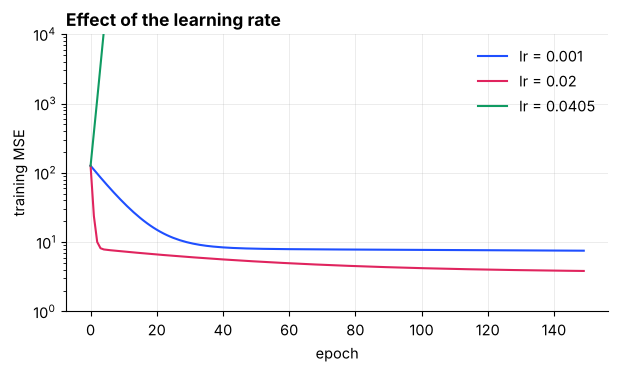

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for lr in [0.001, 0.02, 0.0405]:
    _, h = gradient_descent(X_train, y_train, lr=lr, epochs=150)
    ax.plot(h, label=f"lr = {lr}")
ax.set(yscale="log", xlabel="epoch", ylabel="training MSE", title="Effect of the learning rate")
ax.set_ylim(1, 1e4)
ax.legend()
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig, ax = plt.subplots(figsize=(7, 3.6))</code></td><td>One figure with one panel.</td></tr>
<tr><td><code>for lr in [0.001, 0.02, 0.0405]:</code></td><td>Three learning rates to compare.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;_, h = gradient_descent(X_train, y_train, lr=lr, epochs=150)</code></td><td>Train; keep only the loss history (<code>_</code> discards the weights).</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;ax.plot(h, label=f&quot;lr = {lr}&quot;)</code></td><td>One curve per learning rate.</td></tr>
<tr><td><code>ax.set(yscale=&quot;log&quot;, xlabel=&quot;epoch&quot;, ylabel=&quot;training MSE&quot;, title=&quot;Effect of the learning rate&quot;)</code></td><td>Log scale, labels and title.</td></tr>
<tr><td><code>ax.set_ylim(1, 1e4)</code></td><td>Cap the y-axis so the exploding curve doesn&#x27;t squash the others.</td></tr>
<tr><td><code>ax.legend()</code></td><td>Show a legend built from each plotted series&#x27; <code>label</code>.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

> **🐞 Bug hunt** · **Loss goes up, or becomes `inf` / `nan`**
>
> The learning rate is too large (or features are on very different scales, which has the same effect). Lower the learning rate by 10x, and standardise your features.

## 10.5 Why feature scaling matters · *Intermediate*

**Standardisation, fitted on training data only**

In [7]:
X2 = np.column_stack([rng.uniform(0, 1, n), rng.uniform(0, 1000, n)])
mu = X2[train_idx].mean(axis=0)
sd = X2[train_idx].std(axis=0)
X2_train = (X2[train_idx] - mu) / sd
X2_test = (X2[test_idx] - mu) / sd
print(X2_train.mean(axis=0).round(3), X2_train.std(axis=0).round(3))
print(X2_test.mean(axis=0).round(3))

[-0.  0.] [1. 1.]
[0.027 0.203]


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>X2 = np.column_stack([rng.uniform(0, 1, n), rng.uniform(0, 1000, n)])</code></td><td>Two features on wildly different scales.</td></tr>
<tr><td><code>mu = X2[train_idx].mean(axis=0)</code></td><td>Compute mean and SD from the TRAINING rows only...</td></tr>
<tr><td><code>sd = X2[train_idx].std(axis=0)</code></td><td>Column standard deviations from training rows only.</td></tr>
<tr><td><code>X2_train = (X2[train_idx] - mu) / sd</code></td><td>...and apply the same numbers to train...</td></tr>
<tr><td><code>X2_test = (X2[test_idx] - mu) / sd</code></td><td>...and test. Never recompute them on the test set.</td></tr>
<tr><td><code>print(X2_train.mean(axis=0).round(3), X2_train.std(axis=0).round(3))</code></td><td>Train: mean ~0, SD ~1.</td></tr>
<tr><td><code>print(X2_test.mean(axis=0).round(3))</code></td><td>Test: close to 0 but not exactly, as it should be.</td></tr>
</table>
</details>

> **🔬 Research practice** · **Data leakage starts here**
>
> If you compute scaling statistics on the *whole* dataset before splitting, information about the test set leaks into training and your test score becomes optimistic. scikit-learn's `Pipeline` ([Chapter 20](../part-5-scikit-learn/20-sklearn-preprocessing.ipynb)) makes the correct procedure automatic.

## 10.6 Logistic regression from scratch · *Advanced*

> **📖 Definitions**
>
> **Sigmoid function**: σ(z) = 1 / (1 + e⁻ᶻ), which squashes any number into the range 0–1 so it can be read as a probability.
>
> **Cross-entropy (log loss)**: the standard loss for classification. It heavily penalises confident wrong predictions.
>
> **Decision boundary**: the line or surface in feature space where a classifier switches from predicting one class to another.


For binary classification we pass the linear score through the **sigmoid** σ(z) = 1/(1+e⁻ᶻ) to get a probability, and minimise **binary cross-entropy** (log loss).

**A classifier trained by gradient descent**

In [8]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

m = 300
Xc = np.vstack([rng.normal([-1.5, -1.5], 1.0, size=(m // 2, 2)),
                rng.normal([1.5, 1.5], 1.0, size=(m // 2, 2))])
yc = np.r_[np.zeros(m // 2), np.ones(m // 2)]

Xcb = add_bias(Xc)
w = np.zeros(3)
for _ in range(1000):
    p = sigmoid(Xcb @ w)
    grad = Xcb.T @ (p - yc) / m
    w -= 0.5 * grad
p = sigmoid(Xcb @ w)
eps = 1e-12
loss = -np.mean(yc * np.log(p + eps) + (1 - yc) * np.log(1 - p + eps))
acc = np.mean((p >= 0.5) == yc)
print(f"weights={w.round(3)}  log-loss={loss:.3f}  accuracy={acc:.3f}")

weights=[0.33  3.987 2.208]  log-loss=0.033  accuracy=0.990


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>def sigmoid(z):</code></td><td>Define a function <code>sigmoid</code> that takes <code>z</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;return 1 / (1 + np.exp(-z))</code></td><td>Send <code>1 / (1 + np.exp(-z))</code> back to the caller.</td></tr>
<tr><td><code>m = 300</code></td><td>Number of samples in the classification example.</td></tr>
<tr><td><code>Xc = np.vstack([rng.normal([-1.5, -1.5], 1.0, size=(m // 2, 2)),</code></td><td>Class 0: a cloud centred at (-1.5, -1.5).</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;rng.normal([1.5, 1.5], 1.0, size=(m // 2, 2))])</code></td><td>Class 1: a cloud centred at (1.5, 1.5).</td></tr>
<tr><td><code>yc = np.r_[np.zeros(m // 2), np.ones(m // 2)]</code></td><td>np.r_ concatenates: 150 zeros then 150 ones.</td></tr>
<tr><td><code>Xcb = add_bias(Xc)</code></td><td>Add the intercept column.</td></tr>
<tr><td><code>w = np.zeros(3)</code></td><td>Intercept + 2 feature weights, all starting at 0.</td></tr>
<tr><td><code>for _ in range(1000):</code></td><td>Loop over <code>range(1000)</code>, naming each item <code>_</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;p = sigmoid(Xcb @ w)</code></td><td>Predicted probabilities of class 1.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;grad = Xcb.T @ (p - yc) / m</code></td><td>Gradient of the mean log loss (a famously simple formula).</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;w -= 0.5 * grad</code></td><td>Gradient step with learning rate 0.5.</td></tr>
<tr><td><code>p = sigmoid(Xcb @ w)</code></td><td>Final predicted probabilities.</td></tr>
<tr><td><code>eps = 1e-12</code></td><td>Avoid log(0).</td></tr>
<tr><td><code>loss = -np.mean(yc * np.log(p + eps) + (1 - yc) * np.log(1 - p + eps))</code></td><td>Binary cross-entropy (log loss) over all samples.</td></tr>
<tr><td><code>acc = np.mean((p &gt;= 0.5) == yc)</code></td><td>Threshold probabilities at 0.5 to get class labels.</td></tr>
<tr><td><code>print(f&quot;weights={w.round(3)}  log-loss={loss:.3f}  accuracy={acc:.3f}&quot;)</code></td><td>Learned weights, final loss and accuracy.</td></tr>
</table>
</details>

**Plot the decision boundary**

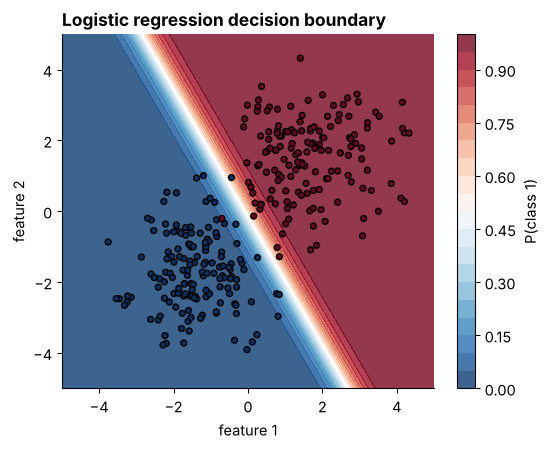

In [9]:
xx, yy = np.meshgrid(np.linspace(-5, 5, 200), np.linspace(-5, 5, 200))
grid = np.column_stack([xx.ravel(), yy.ravel()])
probs = sigmoid(add_bias(grid) @ w).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(6, 4.6))
cs = ax.contourf(xx, yy, probs, levels=20, cmap="RdBu_r", alpha=0.8)
ax.contour(xx, yy, probs, levels=[0.5], colors="white", linewidths=2)
ax.scatter(Xc[:, 0], Xc[:, 1], c=yc, cmap="RdBu_r", edgecolor="k", s=18)
fig.colorbar(cs, label="P(class 1)")
ax.set(title="Logistic regression decision boundary", xlabel="feature 1", ylabel="feature 2")
ax.grid(False)
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>xx, yy = np.meshgrid(np.linspace(-5, 5, 200), np.linspace(-5, 5, 200))</code></td><td>A 200x200 grid covering the plot.</td></tr>
<tr><td><code>grid = np.column_stack([xx.ravel(), yy.ravel()])</code></td><td>Flatten into a list of (x, y) points.</td></tr>
<tr><td><code>probs = sigmoid(add_bias(grid) @ w).reshape(xx.shape)</code></td><td>Predict every grid point, then reshape back.</td></tr>
<tr><td><code>fig, ax = plt.subplots(figsize=(6, 4.6))</code></td><td>One panel, slightly taller than wide.</td></tr>
<tr><td><code>cs = ax.contourf(xx, yy, probs, levels=20, cmap=&quot;RdBu_r&quot;, alpha=0.8)</code></td><td>Filled contours of probability.</td></tr>
<tr><td><code>ax.contour(xx, yy, probs, levels=[0.5], colors=&quot;white&quot;, linewidths=2)</code></td><td>The boundary where p = 0.5.</td></tr>
<tr><td><code>ax.scatter(Xc[:, 0], Xc[:, 1], c=yc, cmap=&quot;RdBu_r&quot;, edgecolor=&quot;k&quot;, s=18)</code></td><td>The data points, coloured by true class.</td></tr>
<tr><td><code>fig.colorbar(cs, label=&quot;P(class 1)&quot;)</code></td><td>A colour bar explains the background shading.</td></tr>
<tr><td><code>ax.set(title=&quot;Logistic regression decision boundary&quot;, xlabel=&quot;feature 1&quot;, ylabel=&quot;feature 2&quot;)</code></td><td>Title and axis labels.</td></tr>
<tr><td><code>ax.grid(False)</code></td><td>Turn off the grid lines on this panel.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

## 10.7 Softmax and one-hot encoding · *Advanced*

> **📖 Definitions**
>
> **Softmax**: a function turning a vector of scores into probabilities that are positive and sum to 1. Used for multiclass outputs.
>
> **One-hot encoding**: representing a category as a vector of 0s with a single 1 in the position of that category, such as class 2 of 4 → `[0, 0, 1, 0]`.


For more than two classes, **softmax** turns a vector of scores into probabilities that sum to 1. Labels are often **one-hot encoded** to match.

**Numerically stable softmax and one-hot labels**

In [10]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

scores = np.array([[2.0, 1.0, 0.1],
                   [1000.0, 1001.0, 999.0]])
print(softmax(scores).round(3))
labels = np.array([0, 2, 1, 2])
one_hot = np.eye(3)[labels]
print(one_hot)
print(one_hot.argmax(axis=1))

[[0.659 0.242 0.099]
 [0.245 0.665 0.09 ]]
[[1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [0. 0. 1.]]
[0 2 1 2]


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>def softmax(z):</code></td><td>Define a function <code>softmax</code> that takes <code>z</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;z = z - z.max(axis=1, keepdims=True)</code></td><td>Subtracting the row max prevents overflow in exp() without changing the result.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;e = np.exp(z)</code></td><td>Exponentiate the shifted scores.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;return e / e.sum(axis=1, keepdims=True)</code></td><td>Normalise each row so it sums to 1.</td></tr>
<tr><td><code>scores = np.array([[2.0, 1.0, 0.1],</code></td><td>Raw scores for two samples and three classes: first row...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1000.0, 1001.0, 999.0]])</code></td><td>The second row would overflow a naive exp().</td></tr>
<tr><td><code>print(softmax(scores).round(3))</code></td><td>Each row now sums to 1, with no overflow.</td></tr>
<tr><td><code>labels = np.array([0, 2, 1, 2])</code></td><td>Integer class labels.</td></tr>
<tr><td><code>one_hot = np.eye(3)[labels]</code></td><td>Index rows of the identity matrix: a neat one-hot trick.</td></tr>
<tr><td><code>print(one_hot)</code></td><td>Display the value of <code>one_hot</code>.</td></tr>
<tr><td><code>print(one_hot.argmax(axis=1))</code></td><td>argmax reverses it.</td></tr>
</table>
</details>

## 10.8 k-nearest neighbours in five lines · *Advanced*

**kNN classifier using broadcasting**

In [11]:
def knn_predict(X_train, y_train, X_new, k=5):
    d = np.sqrt(((X_new[:, None, :] - X_train[None, :, :]) ** 2).sum(-1))
    nearest = np.argsort(d, axis=1)[:, :k]
    votes = y_train[nearest]
    return (votes.mean(axis=1) >= 0.5).astype(int)

perm = rng.permutation(m)
tr, te = perm[:240], perm[240:]
pred = knn_predict(Xc[tr], yc[tr], Xc[te], k=7)
print("kNN test accuracy:", np.mean(pred == yc[te]))

kNN test accuracy: 0.9833333333333333


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>def knn_predict(X_train, y_train, X_new, k=5):</code></td><td>Define a function <code>knn_predict</code> that takes <code>X_train</code>, <code>y_train</code>, <code>X_new</code> and <code>k</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;d = np.sqrt(((X_new[:, None, :] - X_train[None, :, :]) ** 2).sum(-1))</code></td><td>(n_new, n_train) distance matrix.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;nearest = np.argsort(d, axis=1)[:, :k]</code></td><td>Indices of the k closest training points.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;votes = y_train[nearest]</code></td><td>Their labels, shape (n_new, k).</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;return (votes.mean(axis=1) &gt;= 0.5).astype(int)</code></td><td>Majority vote (binary labels 0/1).</td></tr>
<tr><td><code>perm = rng.permutation(m)</code></td><td>Shuffle the 300 indices.</td></tr>
<tr><td><code>tr, te = perm[:240], perm[240:]</code></td><td>240 training and 60 test indices.</td></tr>
<tr><td><code>pred = knn_predict(Xc[tr], yc[tr], Xc[te], k=7)</code></td><td>Predict the test points from their 7 nearest training points.</td></tr>
<tr><td><code>print(&quot;kNN test accuracy:&quot;, np.mean(pred == yc[te]))</code></td><td>Share of correct predictions.</td></tr>
</table>
</details>

> **🔑 Key idea** · **What you just built**
>
> Train/test split, scaling, a regression model (two ways), gradient descent, a classifier, a decision boundary, softmax and kNN. scikit-learn implements all of these, faster and with many more safeguards, but the ideas are exactly the ones above.

> **✍️ Try it yourself**
>
> 1. Add L2 regularisation to `gradient_descent`: add `2 * alpha * w` to the gradient (excluding the intercept) and watch the slope shrink as `alpha` grows.
> 2. Change the logistic regression's class centres to (−0.5, −0.5) and (0.5, 0.5). What happens to accuracy, and why?
> 3. Make `knn_predict` work for more than two classes using `np.bincount` per row.
>
> *Worked solutions:* [solutions-parts-1-4.ipynb](../../solutions/solutions-parts-1-4.ipynb), section *Chapter 10*.

---

⬅️ [Chapter 9: Computing with NumPy: vectorization, broadcasting, statistics, linear algebra](09-numpy-compute.ipynb) · [📚 Contents](../../book/README.md) · [Chapter 11: pandas foundations: Series, DataFrames and selection](../part-3-pandas/11-pandas-basics.ipynb) ➡️